In [ ]:
import pandas as pd
import numpy as np
import zipfile
import os
import glob

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving archive (4).zip to archive (4).zip


In [ ]:
zip_file = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall("queueless_data")

print("ZIP extracted successfully!")

ZIP extracted successfully!


In [ ]:
for root, dirs, files_list in os.walk("queueless_data"):
    for file in files_list:
        print(os.path.join(root, file))

queueless_data/POS_operator_logs_20190213-20190226.csv
queueless_data/POS_transactions_20171207-20171219.csv
queueless_data/POS_transactions_20190213-20190226.csv
queueless_data/POS_operator_logs_20171207-20171219.csv
queueless_data/POS_transactions_20190328-20190410.csv
queueless_data/POS_operator_logs_20190328-20190410.csv


In [ ]:
transaction_files = glob.glob(
    "queueless_data/POS_transactions_*.csv"
)

print("Transaction files:")
for file in transaction_files:
    print(file)

Transaction files:
queueless_data/POS_transactions_20171207-20171219.csv
queueless_data/POS_transactions_20190213-20190226.csv
queueless_data/POS_transactions_20190328-20190410.csv


In [ ]:
dfs = []

for file in transaction_files:
    df = pd.read_csv(file)
    dfs.append(df)

print("Number of files loaded:", len(dfs))

Number of files loaded: 3


In [ ]:
for i, df in enumerate(dfs):
    print(f"Dataset {i+1}:")
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])
    print()

Dataset 1:
Rows: 66863
Columns: 11

Dataset 2:
Rows: 47066
Columns: 11

Dataset 3:
Rows: 49340
Columns: 11



In [ ]:
transactions = pd.concat(
    dfs,
    ignore_index=True
)

print("Combined dataset shape:", transactions.shape)

Combined dataset shape: (163269, 11)


In [ ]:
transactions.head()

,WorkstationGroupID,TranID,BeginDateTime,EndDateTime,OperatorID,TranTime,BreakTime,ArtNum,TNcash,TNcard,Amount
0,1,1.712071e+14,2017-12-07T14:23:23,2017-12-07T14:24:36,101,73,33,23,True,False,112.71
1,1,1.712071e+14,2017-12-07T14:25:09,2017-12-07T14:27:00,101,111,28,29,True,False,54.76
2,1,1.712071e+14,2017-12-07T14:27:28,2017-12-07T14:27:48,101,20,16,3,True,False,14.77
3,1,1.712071e+14,2017-12-07T14:28:04,2017-12-07T14:28:29,101,25,71,12,True,False,37.88
4,1,1.712071e+14,2017-12-07T14:29:40,2017-12-07T14:30:32,101,52,31,7,True,False,115.34


In [ ]:
transactions.columns

Index(['WorkstationGroupID', 'TranID', 'BeginDateTime', 'EndDateTime',
       'OperatorID', 'TranTime', 'BreakTime', 'ArtNum', 'TNcash', 'TNcard',
       'Amount'],
      dtype='object')

In [ ]:
transactions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 163269 entries, 0 to 163268
Data columns (total 11 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   WorkstationGroupID  163269 non-null  int64  
 1   TranID              163269 non-null  float64
 2   BeginDateTime       163269 non-null  object 
 3   EndDateTime         163269 non-null  object 
 4   OperatorID          163269 non-null  int64  
 5   TranTime            163269 non-null  int64  
 6   BreakTime           163269 non-null  int64  
 7   ArtNum              163269 non-null  int64  
 8   TNcash              163269 non-null  bool   
 9   TNcard              163269 non-null  bool   
 10  Amount              163269 non-null  float64
dtypes: bool(2), float64(2), int64(5), object(2)
memory usage: 11.5+ MB


In [ ]:
transactions.isnull().sum()

,0
WorkstationGroupID,0
TranID,0
BeginDateTime,0
EndDateTime,0
OperatorID,0
TranTime,0
BreakTime,0
ArtNum,0
TNcash,0
TNcard,0


In [ ]:
transactions.duplicated().sum()

np.int64(0)

In [ ]:
transactions.describe()

,WorkstationGroupID,TranID,OperatorID,TranTime,BreakTime,ArtNum,Amount
count,163269.000000,1.632690e+05,163269.000000,163269.000000,163269.000000,163269.000000,163269.000000
mean,2.717619,9.676049e+13,194.904618,71.232812,42.133234,15.528563,72.631394
std,3.012171,8.752573e+13,104.048985,60.634477,72.566612,16.398774,87.061413
min,1.000000,1.712071e+11,10.000000,0.000000,-12.000000,1.000000,-3.440000
25%,1.000000,1.902191e+13,114.000000,31.000000,13.000000,5.000000,20.990000
50%,1.000000,1.904101e+13,132.000000,55.000000,21.000000,10.000000,45.910000
75%,1.000000,1.712181e+14,268.000000,92.000000,40.000000,20.000000,93.100000
max,8.000000,1.712121e+15,606.000000,1137.000000,1199.000000,500.000000,6883.500000


In [ ]:
transactions[transactions.isnull().any(axis=1)]

,WorkstationGroupID,TranID,BeginDateTime,EndDateTime,OperatorID,TranTime,BreakTime,ArtNum,TNcash,TNcard,Amount


In [ ]:
transactions[transactions["ArtNum"] < 0]

,WorkstationGroupID,TranID,BeginDateTime,EndDateTime,OperatorID,TranTime,BreakTime,ArtNum,TNcash,TNcard,Amount


In [ ]:
transactions[transactions["Amount"] < 0]

,WorkstationGroupID,TranID,BeginDateTime,EndDateTime,OperatorID,TranTime,BreakTime,ArtNum,TNcash,TNcard,Amount
151876,8,1.904101e+14,2019-04-10T11:04:34,2019-04-10T11:04:45,268,11,108,1,False,False,-3.44
153719,8,1.904021e+14,2019-04-02T14:34:35,2019-04-02T14:34:45,269,10,49,1,False,False,-0.25
154835,8,1.904061e+14,2019-04-06T10:26:49,2019-04-06T10:27:01,269,12,22,1,False,False,-2.51


In [ ]:
transactions[transactions["ArtNum"] > 100]

,WorkstationGroupID,TranID,BeginDateTime,EndDateTime,OperatorID,TranTime,BreakTime,ArtNum,TNcash,TNcard,Amount
296,1,1.712081e+13,2017-12-08T14:39:01,2017-12-08T14:42:39,101,218,11,101,False,True,338.89
661,1,1.712111e+14,2017-12-11T17:03:24,2017-12-11T17:13:46,101,622,57,156,False,True,952.67
1458,1,1.712161e+14,2017-12-16T16:40:08,2017-12-16T16:44:10,101,242,20,111,False,True,509.46
1674,1,1.712181e+14,2017-12-18T09:30:28,2017-12-18T09:36:53,101,385,40,200,False,True,799.30
1776,1,1.712181e+13,2017-12-18T12:26:02,2017-12-18T12:30:51,101,289,32,108,True,False,316.32
...,...,...,...,...,...,...,...,...,...,...,...
162039,1,1.904031e+14,2019-04-03T21:15:16,2019-04-03T21:19:11,387,235,19,103,False,True,243.49
162145,1,1.903301e+14,2019-03-30T18:54:19,2019-03-30T18:57:59,600,220,28,103,True,False,414.93
162431,1,1.903301e+13,2019-03-30T11:02:16,2019-03-30T11:05:29,603,193,20,101,False,True,581.81
162625,1,1.904061e+14,2019-04-06T11:50:38,2019-04-06T11:54:23,603,225,12,103,False,True,323.39


In [ ]:
transactions.isnull().sum()

,0
WorkstationGroupID,0
TranID,0
BeginDateTime,0
EndDateTime,0
OperatorID,0
TranTime,0
BreakTime,0
ArtNum,0
TNcash,0
TNcard,0


In [ ]:
transactions[transactions.isnull().any(axis=1)]

,WorkstationGroupID,TranID,BeginDateTime,EndDateTime,OperatorID,TranTime,BreakTime,ArtNum,TNcash,TNcard,Amount


In [ ]:
transactions.dropna()

,WorkstationGroupID,TranID,BeginDateTime,EndDateTime,OperatorID,TranTime,BreakTime,ArtNum,TNcash,TNcard,Amount
0,1,1.712071e+14,2017-12-07T14:23:23,2017-12-07T14:24:36,101,73,33,23,True,False,112.71
1,1,1.712071e+14,2017-12-07T14:25:09,2017-12-07T14:27:00,101,111,28,29,True,False,54.76
2,1,1.712071e+14,2017-12-07T14:27:28,2017-12-07T14:27:48,101,20,16,3,True,False,14.77
3,1,1.712071e+14,2017-12-07T14:28:04,2017-12-07T14:28:29,101,25,71,12,True,False,37.88
4,1,1.712071e+14,2017-12-07T14:29:40,2017-12-07T14:30:32,101,52,31,7,True,False,115.34
...,...,...,...,...,...,...,...,...,...,...,...
163264,1,1.904101e+14,2019-04-10T14:05:20,2019-04-10T14:06:14,606,54,25,7,True,False,12.14
163265,1,1.904101e+14,2019-04-10T14:06:39,2019-04-10T14:07:35,606,56,16,24,False,True,99.90
163266,1,1.904101e+14,2019-04-10T14:07:51,2019-04-10T14:09:27,606,96,19,47,True,False,106.99
163267,1,1.904101e+14,2019-04-10T14:09:46,2019-04-10T14:10:03,606,17,26,4,True,False,30.88


In [ ]:
transactions.duplicated().sum()

np.int64(0)

In [ ]:
transactions["TranID"].duplicated().sum()

np.int64(36310)

In [ ]:
duplicate_tranids = transactions[
    transactions["TranID"].duplicated(keep=False)
].sort_values("TranID")

duplicate_tranids.head(20)

,WorkstationGroupID,TranID,BeginDateTime,EndDateTime,OperatorID,TranTime,BreakTime,ArtNum,TNcash,TNcard,Amount
98713,1,1.902161e+12,2019-02-16T10:01:37,2019-02-16T10:03:27,303,110,18,36,False,True,122.21
71252,1,1.902161e+12,2019-02-16T12:02:37,2019-02-16T12:07:06,106,269,15,98,False,True,341.16
71254,1,1.902161e+12,2019-02-16T12:07:42,2019-02-16T12:09:45,106,123,12,58,False,True,193.20
98714,1,1.902161e+12,2019-02-16T10:03:45,2019-02-16T10:04:11,303,26,25,8,True,False,74.30
71258,1,1.902161e+12,2019-02-16T12:14:05,2019-02-16T12:14:21,106,16,11,2,True,False,6.78
111973,1,1.902161e+12,2019-02-16T08:01:58,2019-02-16T08:03:21,346,83,18,18,True,False,88.04
111974,1,1.902161e+12,2019-02-16T08:03:39,2019-02-16T08:05:20,346,101,44,27,True,False,141.27
71259,1,1.902161e+12,2019-02-16T12:14:32,2019-02-16T12:16:21,106,109,10,31,False,True,197.67
75503,1,1.902211e+12,2019-02-21T08:20:21,2019-02-21T08:20:35,111,14,17,4,True,False,17.16
110541,1,1.902211e+12,2019-02-21T12:13:16,2019-02-21T12:14:02,342,46,27,15,False,True,34.06


In [ ]:
transactions["TranID"].value_counts().head(20)

,count
TranID,
1.904041e+13,2056
1.904061e+13,1946
1.904051e+13,1689
1.903301e+13,1669
1.904011e+13,1669
1.904101e+13,1665
1.903281e+13,1631
1.904031e+13,1478
1.903291e+13,1331


In [ ]:
duplicate_tranids[
    ["TranID", "WorkstationGroupID", "BeginDateTime", "EndDateTime", "TranTime"]
].head(20)

,TranID,WorkstationGroupID,BeginDateTime,EndDateTime,TranTime
98713,1.902161e+12,1,2019-02-16T10:01:37,2019-02-16T10:03:27,110
71252,1.902161e+12,1,2019-02-16T12:02:37,2019-02-16T12:07:06,269
71254,1.902161e+12,1,2019-02-16T12:07:42,2019-02-16T12:09:45,123
98714,1.902161e+12,1,2019-02-16T10:03:45,2019-02-16T10:04:11,26
71258,1.902161e+12,1,2019-02-16T12:14:05,2019-02-16T12:14:21,16
111973,1.902161e+12,1,2019-02-16T08:01:58,2019-02-16T08:03:21,83
111974,1.902161e+12,1,2019-02-16T08:03:39,2019-02-16T08:05:20,101
71259,1.902161e+12,1,2019-02-16T12:14:32,2019-02-16T12:16:21,109
75503,1.902211e+12,1,2019-02-21T08:20:21,2019-02-21T08:20:35,14
110541,1.902211e+12,1,2019-02-21T12:13:16,2019-02-21T12:14:02,46


In [ ]:
transactions.drop_duplicates("TranID")

,WorkstationGroupID,TranID,BeginDateTime,EndDateTime,OperatorID,TranTime,BreakTime,ArtNum,TNcash,TNcard,Amount
0,1,1.712071e+14,2017-12-07T14:23:23,2017-12-07T14:24:36,101,73,33,23,True,False,112.71
1,1,1.712071e+14,2017-12-07T14:25:09,2017-12-07T14:27:00,101,111,28,29,True,False,54.76
2,1,1.712071e+14,2017-12-07T14:27:28,2017-12-07T14:27:48,101,20,16,3,True,False,14.77
3,1,1.712071e+14,2017-12-07T14:28:04,2017-12-07T14:28:29,101,25,71,12,True,False,37.88
4,1,1.712071e+14,2017-12-07T14:29:40,2017-12-07T14:30:32,101,52,31,7,True,False,115.34
...,...,...,...,...,...,...,...,...,...,...,...
162480,1,1.904021e+11,2019-04-02T11:08:22,2019-04-02T11:09:14,603,52,16,8,True,False,24.93
162481,1,1.904021e+11,2019-04-02T11:09:30,2019-04-02T11:10:04,603,34,17,17,True,False,51.71
162482,1,1.904021e+11,2019-04-02T11:10:21,2019-04-02T11:11:03,603,42,10,19,True,False,41.95
162483,1,1.904021e+11,2019-04-02T11:11:13,2019-04-02T11:11:42,603,29,12,9,False,True,47.96


In [ ]:
transactions.drop_duplicates("TranID")

,WorkstationGroupID,TranID,BeginDateTime,EndDateTime,OperatorID,TranTime,BreakTime,ArtNum,TNcash,TNcard,Amount
0,1,1.712071e+14,2017-12-07T14:23:23,2017-12-07T14:24:36,101,73,33,23,True,False,112.71
1,1,1.712071e+14,2017-12-07T14:25:09,2017-12-07T14:27:00,101,111,28,29,True,False,54.76
2,1,1.712071e+14,2017-12-07T14:27:28,2017-12-07T14:27:48,101,20,16,3,True,False,14.77
3,1,1.712071e+14,2017-12-07T14:28:04,2017-12-07T14:28:29,101,25,71,12,True,False,37.88
4,1,1.712071e+14,2017-12-07T14:29:40,2017-12-07T14:30:32,101,52,31,7,True,False,115.34
...,...,...,...,...,...,...,...,...,...,...,...
162480,1,1.904021e+11,2019-04-02T11:08:22,2019-04-02T11:09:14,603,52,16,8,True,False,24.93
162481,1,1.904021e+11,2019-04-02T11:09:30,2019-04-02T11:10:04,603,34,17,17,True,False,51.71
162482,1,1.904021e+11,2019-04-02T11:10:21,2019-04-02T11:11:03,603,42,10,19,True,False,41.95
162483,1,1.904021e+11,2019-04-02T11:11:13,2019-04-02T11:11:42,603,29,12,9,False,True,47.96


In [ ]:
transactions.duplicated(
    subset=["TranID", "BeginDateTime", "WorkstationGroupID"]
).sum()

np.int64(252)

In [ ]:
transactions["BeginDateTime"] = pd.to_datetime(
    transactions["BeginDateTime"]
)

transactions["EndDateTime"] = pd.to_datetime(
    transactions["EndDateTime"]
)

transactions["calculated_TranTime"] = (
    transactions["EndDateTime"] - transactions["BeginDateTime"]
).dt.total_seconds()

transactions[[
    "TranTime",
    "calculated_TranTime"
]].head(10)

,TranTime,calculated_TranTime
0,73,73.0
1,111,111.0
2,20,20.0
3,25,25.0
4,52,52.0
5,58,58.0
6,218,218.0
7,43,43.0
8,36,36.0
9,51,51.0


In [ ]:
transactions["time_difference"] = (
    transactions["EndDateTime"] - transactions["BeginDateTime"]
).dt.total_seconds()

print(
    "Rows where TranTime != calculated time:",
    (transactions["TranTime"] != transactions["time_difference"]).sum()
)

Rows where TranTime != calculated time: 0


In [ ]:
transactions[[
    "TranTime",
    "time_difference"
]].describe()

,TranTime,time_difference
count,163269.000000,163269.000000
mean,71.232812,71.232812
std,60.634477,60.634477
min,0.000000,0.000000
25%,31.000000,31.000000
50%,55.000000,55.000000
75%,92.000000,92.000000
max,1137.000000,1137.000000


In [ ]:
transactions.drop(
    columns=["time_difference", "calculated_TranTime"],
    errors="ignore",
    inplace=True
)

In [ ]:
transactions.shape

(163269, 11)

In [ ]:
transactions["hour"] = transactions["BeginDateTime"].dt.hour

transactions["day_of_week"] = (
    transactions["BeginDateTime"].dt.day_name()
)

transactions["date"] = (
    transactions["BeginDateTime"].dt.date
)

transactions["is_weekend"] = (
    transactions["BeginDateTime"].dt.dayofweek >= 5
)

In [ ]:
transactions[
    ["BeginDateTime", "hour", "day_of_week", "date", "is_weekend"]
].head()

,BeginDateTime,hour,day_of_week,date,is_weekend
0,2017-12-07 14:23:23,14,Thursday,2017-12-07,False
1,2017-12-07 14:25:09,14,Thursday,2017-12-07,False
2,2017-12-07 14:27:28,14,Thursday,2017-12-07,False
3,2017-12-07 14:28:04,14,Thursday,2017-12-07,False
4,2017-12-07 14:29:40,14,Thursday,2017-12-07,False


In [ ]:
hourly_transactions = (
    transactions
    .groupby("hour")
    .size()
    .reset_index(name="transaction_count")
)

hourly_transactions

,hour,transaction_count
0,6,315
1,7,5817
2,8,8018
3,9,10157
4,10,12842
5,11,14153
6,12,14146
7,13,13625
8,14,12849
9,15,11967


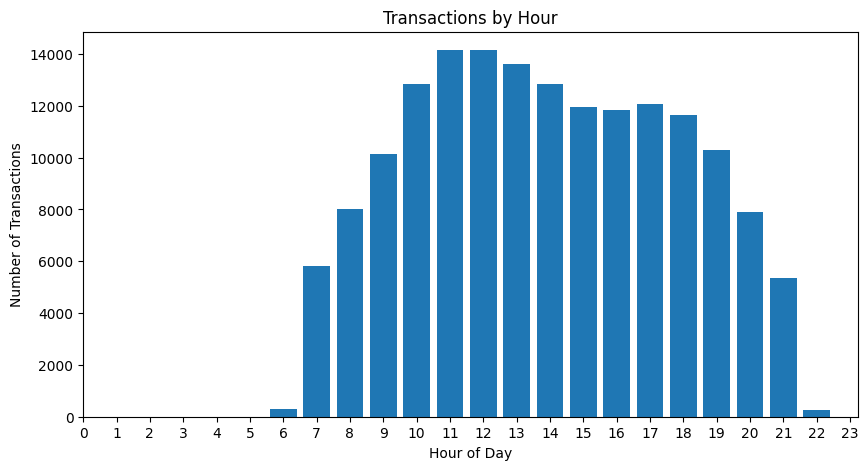

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    hourly_transactions["hour"],
    hourly_transactions["transaction_count"]
)

plt.xlabel("Hour of Day")
plt.ylabel("Number of Transactions")
plt.title("Transactions by Hour")

plt.xticks(range(24))
plt.show()

In [ ]:
daily_transactions = (
    transactions
    .groupby("day_of_week")
    .size()
)

daily_transactions

,0
day_of_week,
Friday,28116
Monday,23473
Saturday,29244
Sunday,12768
Thursday,29738
Tuesday,22484
Wednesday,17446


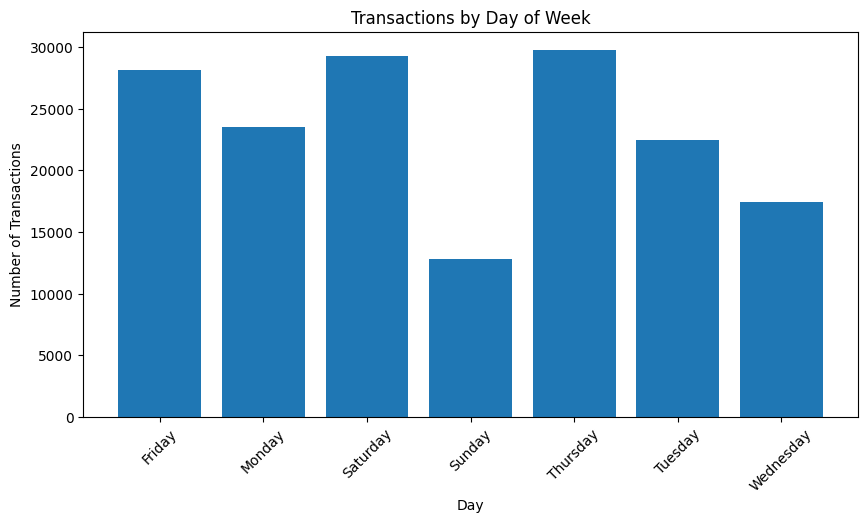

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    daily_transactions.index,
    daily_transactions.values
)

plt.xlabel("Day")
plt.ylabel("Number of Transactions")
plt.title("Transactions by Day of Week")

plt.xticks(rotation=45)
plt.show()

In [ ]:
avg_service_by_hour = (
    transactions
    .groupby("hour")["TranTime"]
    .mean()
    .reset_index()
)

avg_service_by_hour

,hour,TranTime
0,6,48.352381
1,7,69.214887
2,8,71.403592
3,9,70.915231
4,10,68.777449
5,11,69.466191
6,12,70.066662
7,13,70.488881
8,14,69.367655
9,15,71.430852


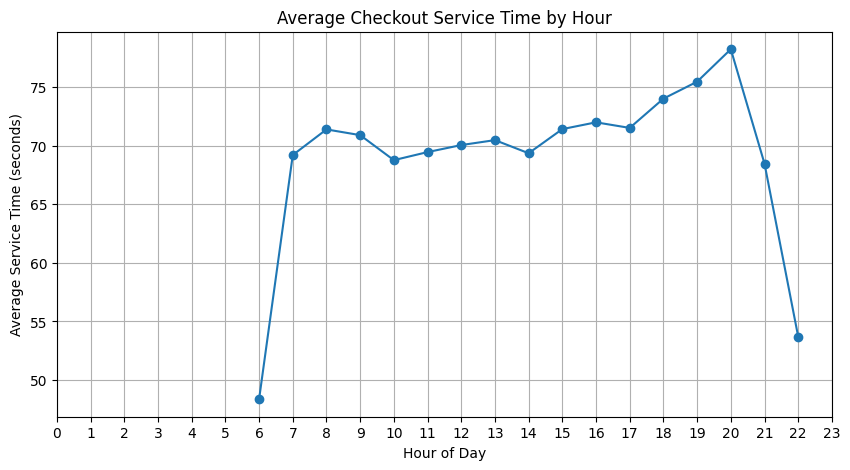

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    avg_service_by_hour["hour"],
    avg_service_by_hour["TranTime"],
    marker="o"
)

plt.xlabel("Hour of Day")
plt.ylabel("Average Service Time (seconds)")
plt.title("Average Checkout Service Time by Hour")

plt.xticks(range(24))
plt.grid(True)

plt.show()

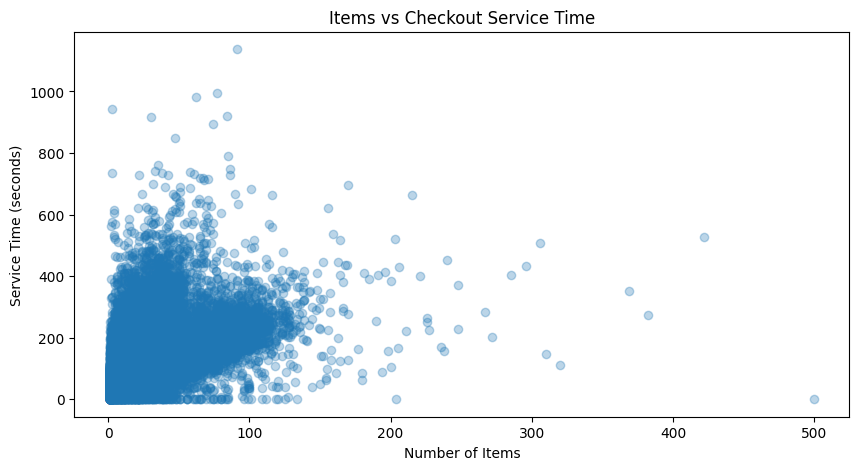

In [ ]:
plt.figure(figsize=(10, 5))

plt.scatter(
    transactions["ArtNum"],
    transactions["TranTime"],
    alpha=0.3
)

plt.xlabel("Number of Items")
plt.ylabel("Service Time (seconds)")
plt.title("Items vs Checkout Service Time")

plt.show()

In [ ]:
counter_service = (
    transactions
    .groupby("WorkstationGroupID")["TranTime"]
    .agg(["count", "mean", "median"])
    .reset_index()
)

counter_service

,WorkstationGroupID,count,mean,median
0,1,123207,62.037441,50.0
1,8,40062,99.512331,77.0


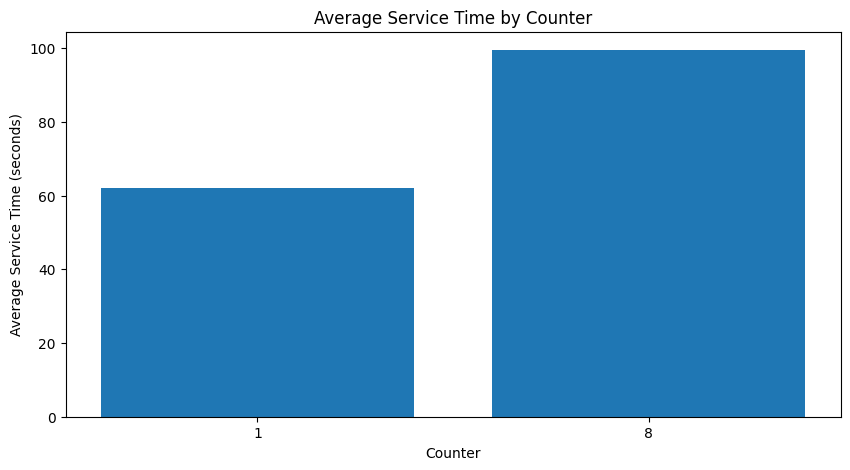

In [ ]:
plt.figure(figsize=(10, 5))

plt.bar(
    counter_service["WorkstationGroupID"].astype(str),
    counter_service["mean"]
)

plt.xlabel("Counter")
plt.ylabel("Average Service Time (seconds)")
plt.title("Average Service Time by Counter")

plt.show()

In [ ]:
transactions["WorkstationGroupID"].value_counts().sort_index()

,count
WorkstationGroupID,
1,123207
8,40062


In [ ]:
transactions["WorkstationGroupID"].unique()

array([1, 8])

In [ ]:
features = [
    "ArtNum",
    "hour",
    "day_of_week",
    "is_weekend",
    "WorkstationGroupID"
]

In [ ]:
target = "TranTime"

In [ ]:
transactions["WorkstationGroupID"].value_counts().sort_index()

,count
WorkstationGroupID,
1,123207
8,40062


In [ ]:
transactions["WorkstationGroupID"].unique()

array([1, 8])

In [ ]:
transactions[
    ~transactions["WorkstationGroupID"].isin([1, 8])
]

,WorkstationGroupID,TranID,BeginDateTime,EndDateTime,OperatorID,TranTime,BreakTime,ArtNum,TNcash,TNcard,Amount,hour,day_of_week,date,is_weekend


In [ ]:
transactions["WorkstationGroupID"].value_counts(dropna=False)

,count
WorkstationGroupID,
1,123207
8,40062


In [ ]:
model_data = transactions[
    [
        "ArtNum",
        "hour",
        "day_of_week",
        "is_weekend",
        "WorkstationGroupID",
        "TranTime"
    ]
].copy()

model_data.head()

,ArtNum,hour,day_of_week,is_weekend,WorkstationGroupID,TranTime
0,23,14,Thursday,False,1,73
1,29,14,Thursday,False,1,111
2,3,14,Thursday,False,1,20
3,12,14,Thursday,False,1,25
4,7,14,Thursday,False,1,52


In [ ]:
model_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 163269 entries, 0 to 163268
Data columns (total 6 columns):
 #   Column              Non-Null Count   Dtype 
---  ------              --------------   ----- 
 0   ArtNum              163269 non-null  int64 
 1   hour                163269 non-null  int32 
 2   day_of_week         163269 non-null  object
 3   is_weekend          163269 non-null  bool  
 4   WorkstationGroupID  163269 non-null  int64 
 5   TranTime            163269 non-null  int64 
dtypes: bool(1), int32(1), int64(3), object(1)
memory usage: 5.8+ MB


In [ ]:
model_data.shape

(163269, 6)

In [ ]:
X = model_data.drop("TranTime", axis=1)
y = model_data["TranTime"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Features:
['ArtNum', 'hour', 'day_of_week', 'is_weekend', 'WorkstationGroupID']

Target:
TranTime


In [ ]:
X = pd.get_dummies(
    X,
    columns=["day_of_week"],
    drop_first=True
)

X.head()

,ArtNum,hour,is_weekend,WorkstationGroupID,day_of_week_Monday,day_of_week_Saturday,day_of_week_Sunday,day_of_week_Thursday,day_of_week_Tuesday,day_of_week_Wednesday
0,23,14,False,1,False,False,False,True,False,False
1,29,14,False,1,False,False,False,True,False,False
2,3,14,False,1,False,False,False,True,False,False
3,12,14,False,1,False,False,False,True,False,False
4,7,14,False,1,False,False,False,True,False,False


In [ ]:
X.dtypes

,0
ArtNum,int64
hour,int32
is_weekend,bool
WorkstationGroupID,int64
day_of_week_Monday,bool
day_of_week_Saturday,bool
day_of_week_Sunday,bool
day_of_week_Thursday,bool
day_of_week_Tuesday,bool
day_of_week_Wednesday,bool


In [ ]:
model_data = transactions[
    [
        "BeginDateTime",
        "ArtNum",
        "hour",
        "day_of_week",
        "is_weekend",
        "WorkstationGroupID",
        "TranTime"
    ]
].copy()

model_data = model_data.sort_values("BeginDateTime")

In [ ]:
# Sort by time
model_data = model_data.sort_values("BeginDateTime").reset_index(drop=True)

# 80% training, 20% testing
split_idx = int(len(model_data) * 0.8)

train = model_data.iloc[:split_idx].copy()
test = model_data.iloc[split_idx:].copy()

print("Training rows:", len(train))
print("Testing rows:", len(test))

print("\nTraining period:")
print(train["BeginDateTime"].min())
print(train["BeginDateTime"].max())

print("\nTesting period:")
print(test["BeginDateTime"].min())
print(test["BeginDateTime"].max())

Training rows: 130615
Testing rows: 32654

Training period:
2017-12-07 06:26:26
2019-04-01 14:00:45

Testing period:
2019-04-01 14:01:07
2019-04-10 22:08:41


In [ ]:
features = [
    "ArtNum",
    "hour",
    "day_of_week",
    "is_weekend",
    "WorkstationGroupID"
]

target = "TranTime"

X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (130615, 5)
y_train: (130615,)
X_test: (32654, 5)
y_test: (32654,)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

categorical_features = [
    "day_of_week",
    "WorkstationGroupID"
]

numeric_features = [
    "ArtNum",
    "hour",
    "is_weekend"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            "passthrough",
            numeric_features
        )
    ]
)

In [ ]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [ ]:
y_pred = model.predict(X_test)

print("Actual service times:")
print(y_test.head(10).values)

print("\nPredicted service times:")
print(y_pred[:10])

Actual service times:
[  6  29  35  75  92 149  57  38  84  26]

Predicted service times:
[ 21.65559883  81.57190902  46.50846269  98.14048493  46.50846269
 122.99334878  49.26989201  35.46274542  89.85619698  38.22417474]


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("\nLinear Regression Performance")
print("-----------------------------")
print(f"MAE  : {mae:.2f} seconds")
print(f"RMSE : {rmse:.2f} seconds")
print(f"R²   : {r2:.3f}")


Linear Regression Performance
-----------------------------
MAE  : 26.45 seconds
RMSE : 42.50 seconds
R²   : 0.444


In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=100,
            max_depth=15,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
y_pred_rf = rf_model.predict(X_test)

print("First 10 actual values:")
print(y_test.head(10).values)

print("\nFirst 10 Random Forest predictions:")
print(y_pred_rf[:10])

First 10 actual values:
[  6  29  35  75  92 149  57  38  84  26]

First 10 Random Forest predictions:
[ 17.48213854  49.60770114  53.84143495 104.60952557  53.84143495
 155.84450479  55.79245541  38.53191059  62.42436959  47.08338436]


In [ ]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

r2_rf = r2_score(y_test, y_pred_rf)

print("\nRandom Forest Performance")
print("-----------------------------")
print(f"MAE  : {mae_rf:.2f} seconds")
print(f"RMSE : {rmse_rf:.2f} seconds")
print(f"R²   : {r2_rf:.3f}")


Random Forest Performance
-----------------------------
MAE  : 23.86 seconds
RMSE : 36.51 seconds
R²   : 0.590


In [ ]:
# Get feature names after one-hot encoding

feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()

importances = rf_model.named_steps["regressor"].feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(
    "Importance",
    ascending=False
)

print(feature_importance)

                               Feature  Importance
9                      numeric__ArtNum    0.686878
8    categorical__WorkstationGroupID_8    0.121485
7    categorical__WorkstationGroupID_1    0.117668
10                       numeric__hour    0.043989
5     categorical__day_of_week_Tuesday    0.004439
0      categorical__day_of_week_Friday    0.004397
4    categorical__day_of_week_Thursday    0.004330
1      categorical__day_of_week_Monday    0.004195
2    categorical__day_of_week_Saturday    0.003629
3      categorical__day_of_week_Sunday    0.003390
6   categorical__day_of_week_Wednesday    0.002854
11                 numeric__is_weekend    0.002747


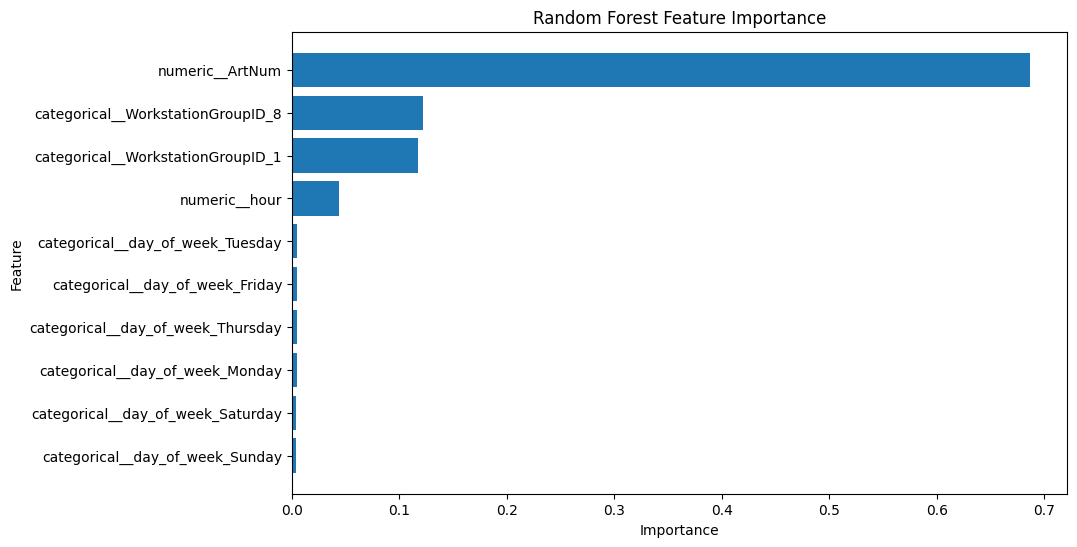

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"].head(10)[::-1],
    feature_importance["Importance"].head(10)[::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.show()

In [ ]:
counter_service_time = (
    transactions
    .groupby("WorkstationGroupID")["TranTime"]
    .mean()
    .reset_index()
)

counter_service_time.columns = [
    "WorkstationGroupID",
    "AverageServiceTime"
]

print(counter_service_time)

   WorkstationGroupID  AverageServiceTime
0                   1           62.037441
1                   8           99.512331


In [ ]:
# ============================================
# QUEUELESS - ML COUNTER RECOMMENDATION most important
# ============================================

# Customer information
customer_art_num = 15
current_hour = 18
current_day = "Monday"
current_weekend = False

# Queue detected at each counter
queue_data = pd.DataFrame({
    "WorkstationGroupID": [1, 8],
    "PeopleInQueue": [5, 2]
})

# --------------------------------------------
# Predict service time for each counter
# --------------------------------------------

predicted_times = []

for counter in queue_data["WorkstationGroupID"]:

    input_data = pd.DataFrame({
        "ArtNum": [customer_art_num],
        "hour": [current_hour],
        "day_of_week": [current_day],
        "is_weekend": [current_weekend],
        "WorkstationGroupID": [counter]
    })

    prediction = rf_model.predict(input_data)[0]

    predicted_times.append(prediction)

queue_data["PredictedServiceTime"] = predicted_times

# --------------------------------------------
# Calculate estimated waiting time
# --------------------------------------------

queue_data["EstimatedWaitSeconds"] = (
    queue_data["PeopleInQueue"]
    * queue_data["PredictedServiceTime"]
)

queue_data["EstimatedWaitMinutes"] = (
    queue_data["EstimatedWaitSeconds"] / 60
)

# --------------------------------------------
# Find best counter
# --------------------------------------------

best_index = queue_data["EstimatedWaitSeconds"].idxmin()

best_counter = queue_data.loc[
    best_index,
    "WorkstationGroupID"
]

best_wait = queue_data.loc[
    best_index,
    "EstimatedWaitMinutes"
]

# --------------------------------------------
# Display results
# --------------------------------------------

print("QUEUE DATA")
print(queue_data)

print("\n===================================")
print("       QUEUELESS RECOMMENDATION")
print("===================================")
print(f"Recommended Counter: {int(best_counter)}")
print(f"Estimated Waiting Time: {best_wait:.2f} minutes")
print("===================================")

QUEUE DATA
   WorkstationGroupID  PeopleInQueue  PredictedServiceTime  \
0                   1              5             56.985437   
1                   8              2            146.899518   

   EstimatedWaitSeconds  EstimatedWaitMinutes  
0            284.927186              4.748786  
1            293.799036              4.896651  

       QUEUELESS RECOMMENDATION
Recommended Counter: 1
Estimated Waiting Time: 4.75 minutes


In [ ]:
# ============================================
# HISTORICAL EXPECTED SERVICE TIME
# ============================================

historical_service = (
    transactions
    .groupby("WorkstationGroupID")["TranTime"]
    .mean()
    .reset_index()
)

historical_service.columns = [
    "WorkstationGroupID",
    "ExpectedQueueServiceTime"
]

print(historical_service)

   WorkstationGroupID  ExpectedQueueServiceTime
0                   1                 62.037441
1                   8                 99.512331


In [ ]:
queue_data = queue_data.merge(
    historical_service,
    on="WorkstationGroupID"
)

queue_data["QueueWaitSeconds"] = (
    queue_data["PeopleInQueue"]
    * queue_data["ExpectedQueueServiceTime"]
)

queue_data["QueueWaitMinutes"] = (
    queue_data["QueueWaitSeconds"] / 60
)

print(queue_data)

   WorkstationGroupID  PeopleInQueue  PredictedServiceTime  \
0                   1              5             56.985437   
1                   8              2            146.899518   

   EstimatedWaitSeconds  EstimatedWaitMinutes  ExpectedQueueServiceTime  \
0            284.927186              4.748786                 62.037441   
1            293.799036              4.896651                 99.512331   

   QueueWaitSeconds  QueueWaitMinutes  
0        310.187205          5.169787  
1        199.024662          3.317078  


In [ ]:
# ============================================
# QUEUELESS - FINAL QUEUE RECOMMENDATION
# ============================================

# Find counter with minimum queue waiting time
best_index = queue_data["QueueWaitSeconds"].idxmin()

best_counter = queue_data.loc[
    best_index,
    "WorkstationGroupID"
]

best_wait = queue_data.loc[
    best_index,
    "QueueWaitMinutes"
]

print("===================================")
print("       QUEUELESS RECOMMENDATION")
print("===================================")

print(f"Recommended Counter: {int(best_counter)}")
print(f"Estimated Queue Wait: {best_wait:.2f} minutes")

print("===================================")

       QUEUELESS RECOMMENDATION
Recommended Counter: 8
Estimated Queue Wait: 3.32 minutes


"We used historical POS transaction data to estimate checkout service time. After combining and cleaning three transaction datasets, we performed exploratory data analysis and found that transaction time varies with factors such as number of articles, checkout counter and time of day. We formulated service-time prediction as a regression problem. We used a chronological train-test split so that the model was evaluated on future transactions. We first trained Linear Regression as a baseline and then Random Forest Regression. Random Forest achieved an MAE of about 23.86 seconds, RMSE of 36.51 seconds and R² of 0.590 on the held-out future data. We then integrated the model with queue estimation. Historical average service times are used to estimate the time required to clear people already waiting, while the Random Forest can predict the current customer's service time for different counters. The next step is to replace the manually simulated queue counts with real-time counts obtained from YOLO."